In [3]:
import geemap
import ee

#ee.Authenticate(force=True)
ee.Initialize(project='ee-sbouchiba')


In [4]:
## Import cities footprint
import geopandas as gpd
import json

city_names = ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
train_city = 'geneva'
#test_city = 'lausanne'

allcity_roi_path = './input/footprints/study_areas.geojson'

#geneva_roi_gpd  = gpd.read_file(geneva_roi_path)
#geneva_roi_gpd  = geneva_roi_gpd.to_crs("EPSG:4326") # convert projected CRS into WGS84 longitude/latitude.
allcity_roi_gpd = gpd.read_file(allcity_roi_path)
allcity_roi_gpd = allcity_roi_gpd.to_crs("EPSG:4326") # convert projected CRS into WGS84 longitude/latitude.


#geom = geneva_roi_gpd.geometry.iloc[0]
geom = {
    "geneva":   allcity_roi_gpd.geometry.iloc[0],
    "lausanne": allcity_roi_gpd.geometry.iloc[1],
    "bern":     allcity_roi_gpd.geometry.iloc[2],
    "basel":    allcity_roi_gpd.geometry.iloc[3],
    "zurich":   allcity_roi_gpd.geometry.iloc[4],
    "lugano":   allcity_roi_gpd.geometry.iloc[5],
    "allcity":  allcity_roi_gpd.union_all(),
}

roi = ee.Geometry(geom[train_city].__geo_interface__)
roi_fc = ee.FeatureCollection([ee.Feature(roi)])


In [5]:
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "GeometryConstructors.MultiPolygon",
    "arguments": {
      "coordinates": {
        "constantValue": [
          [
            [
              [
                6.327351158185084,
                46.37487484976004
              ],
              [
                6.3275123602360726,
                46.123001095457596
              ],
              [
                5.937904960898974,
                46.120312050733816
              ],
              [
                5.928311283195946,
                46.37025319326727
              ],
              [
                6.327351158185084,
                46.37487484976004
              ]
            ]
          ]
        ]
      }
    }
  }
})

In [6]:
## Import train/test datasets

#train_polygons = ee.FeatureCollection('./input/geneva_2022_training_polygons.geojson');
#test_polygons  = ee.FeatureCollection('./input/geneva_2022_testing_polygons.geojson');
import geopandas as gpd
import pandas as pd


## Training samples
if train_city=='allcity':
    centroid_gdfs = []
    polygon_gdfs  = []
    for city in city_names:
        centroid_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_centroids.geojson"
        )
        polygon_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_polygons.geojson"
        )
    
        # Optional: keep track of origin city
        centroid_gdf["city"] = city
        polygon_gdf["city"] = city
    
        centroid_gdfs.append(centroid_gdf)
        polygon_gdfs.append(polygon_gdf)
    
    # Merge all cities
    train_centroids_gdf = gpd.GeoDataFrame(
        pd.concat(centroid_gdfs, ignore_index=True),
        crs=centroid_gdfs[0].crs
    )
    
    train_polygons_gdf = gpd.GeoDataFrame(
        pd.concat(polygon_gdfs, ignore_index=True),
        crs=polygon_gdfs[0].crs
    )

else:
    train_centroids_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_centroids.geojson')
    train_polygons_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_polygons.geojson')
    train_centroids_gdf['city'] = train_city
    train_polygons_gdf['city'] = train_city

#print(train_centroids_gdf.columns)

# Remove signature class for test datasets
train_centroids_gdf = (train_centroids_gdf[train_centroids_gdf["macroclass_id"] != 1].copy())
train_polygons_gdf = (train_polygons_gdf[train_polygons_gdf["macroclass_id"] != 1].copy())

# Re-map: define new class mapping that is simpler to handle
class_mapping = {
    2: 1,   # Compact MR
    5: 2,   # Open MR
    6: 3,   # Open LR
    8: 4,   # Large LR
    11: 5,  # Dense Trees
    14: 6,  # Low plants
    15: 7,  # Bare Rock/Paved
    17: 8   # Water
}

# Some data re-arrangement
train_centroids_gdf["LCZ_class"] = (train_centroids_gdf["macroclass_id"].map(class_mapping))
train_polygons_gdf["LCZ_class"]  = (train_polygons_gdf["macroclass_id"].map(class_mapping))

# Convert to EE datasets
train_centroids = geemap.geopandas_to_ee(train_centroids_gdf)
train_polygons  = geemap.geopandas_to_ee(train_polygons_gdf)

In [39]:
#train_centroids_gdf

### Import DSM (digital surface model)/MNS
* Used model: **swissALTI3D**, use LiDAR and photogrammetry, naked topography (no trees, building etc.)
* Source: https://www.swisstopo.admin.ch/fr/modele-altimetrique-swissalti3d
* Downloaded `.tif` format with 5 meters resolution
* Put in GEE assets:
    * Go to https://code.earthengine.google.com/
    * Select left table "Assets"
    * Add local `.tif` files in EE project.

In [41]:
dem = ee.Image("projects/ee-sbouchiba/assets/geneva_surface3draster_merged")

dem=dem.rename('elevation')
print(dem.bandNames().getInfo())
# convert projected CRS into WGS84 longitude/latitude. 
#dem = dem.resample('bilinear').reproject(
#    crs=embeddingsImage.projection(),
#    scale=10
#)

#scale = 10
#crs = 'EPSG:4326'  # or your study CRS
#dem = dem.reproject(crs=crs, scale=scale)

dem = dem.reproject(
    crs='EPSG:4326',
    scale=10
)


['elevation']


In [38]:
dem

In [9]:
print(dem.projection().getInfo())
print(dem.projection().nominalScale().getInfo())

{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [8.983152841195215e-05, 0, 0, 0, -8.983152841195215e-05, 0]}
10


In [10]:
import rasterio

with rasterio.open("./input/swissALTI3D/Geneva_TIFF_files/geneva_dem_10m.tif") as src:
    print(src.crs)
    print(src.res)
    print(src.bounds)

EPSG:2056
(10.0, 10.0)
BoundingBox(left=2485000.0, bottom=1109000.0, right=2513000.0, top=1136000.0)


In [11]:
## DEBUG

In [42]:
training_emb = embeddingsFiltered.mosaic().sampleRegions(
    collection=train_centroids,
    properties=['LCZ_class'],
    scale=10
)

print(training_emb.size().getInfo())

375


In [ ]:
print(train_centroids.size().getInfo())
print(train_centroids.first().getInfo())

In [ ]:
print(
    train_centroids.geometry().bounds().getInfo()
)

In [ ]:
print(dem.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=train_centroids.first().geometry(),
    scale=10
).getInfo())

In [13]:
print(dem.geometry().bounds().getInfo())

{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[5.944379263741103, 46.12261854692668], [6.3131086128424165, 46.12261854692668], [6.3131086128424165, 46.36076944965415], [5.944379263741103, 46.36076944965415], [5.944379263741103, 46.12261854692668]]]}


In [14]:
Map = geemap.Map()

Map.addLayer(dem, {}, "DEM")
Map.addLayer(train_centroids, {"color": "red"}, "training")

#Map

In [43]:
# Import embeddings
year = 2022;
startDate = ee.Date.fromYMD(year, 1, 1);
endDate = startDate.advance(1, 'year');

embeddings = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL');
embeddingsFiltered = embeddings\
  .filter(ee.Filter.date(startDate, endDate))\
  .filter(ee.Filter.bounds(roi));

embeddingsImage = embeddingsFiltered.mosaic();

In [56]:

# add band
embeddingsImage = embeddingsImage.addBands(dem)
embeddingsImage = embeddings.mosaic();

#Overlay the samples on the image to get training data.
#training = embeddingsImage.sampleRegions(collection = train_centroids, properties=['LCZ_class'], scale=10)

#training = embeddingsImage.sampleRegions(
#    collection=train_centroids,
#    properties=['LCZ_class'],
#    scale=10,
#    tileScale=4
#)

training = embeddingsImage.sampleRegions(
    collection=train_centroids,
    properties=['LCZ_class'],
    scale=10
)

In [57]:
print(dem.geometry().bounds().getInfo())
print(train_centroids.geometry().bounds().getInfo())

{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[5.944379263741103, 46.12261854692668], [6.3131086128424165, 46.12261854692668], [6.3131086128424165, 46.36076944965415], [5.944379263741103, 46.36076944965415], [5.944379263741103, 46.12261854692668]]]}
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[5.942570266994948, 46.12494309217099], [6.327896294477439, 46.12494309217099], [6.327896294477439, 46.37112109958023], [5.942570266994948, 46.37112109958023], [5.942570266994948, 46.12494309217099]]]}


In [58]:
print(dem.projection().getInfo())

{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [8.983152841195215e-05, 0, 0, 0, -8.983152841195215e-05, 0]}


In [19]:
print(dem.projection().nominalScale().getInfo())

10


In [20]:
import geemap

Map = geemap.Map()

Map.addLayer(dem, {'color':'blue'}, 'DEM')
Map.addLayer(train_centroids, {'color':'red'}, 'Points')

#Map

In [ ]:
#print(dem.bandNames().getInfo())
#print(embeddingsImage.bandNames().getInfo())

In [45]:
print(embeddingsImage.projection().getInfo())
print(dem.projection().getInfo())

{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [8.983152841195215e-05, 0, 0, 0, -8.983152841195215e-05, 0]}


In [46]:
print(dem.projection().nominalScale().getInfo())
print(
    dem.select('elevation')
       .projection()
       .nominalScale()
       .getInfo()
)

10
10


In [ ]:
asset = ee.data.getAsset(
    "projects/ee-sbouchiba/assets/geneva_dem_10m"
)

print(asset['bands'])

In [ ]:
print(
    embeddingsFiltered.first()
        .projection()
        .getInfo()
)

print(
    embeddingsFiltered.first()
        .projection()
        .nominalScale()
        .getInfo()
)

In [ ]:
print(
    dem.projection()
       .nominalScale()
       .getInfo()
)

In [ ]:
print(
    ee.data.getAsset(
        "projects/ee-sbouchiba/assets/geneva_dem_10m"
    )['bands']
)

In [ ]:
print(
    dem.select('elevation')
       .projection()
       .getInfo()
)

print(
    dem.select('elevation')
       .projection()
       .nominalScale()
       .getInfo()
)

In [ ]:
print(training.size().getInfo())

### Train a classifier

In [59]:
# Used best Random Forest (optimised on Geneva -> Geneva)
numberOfTrees = 500
variablesPerSplit = 8
minLeafPopulation = 5

#classifier = ee.Classifier.smileGradientTreeBoost(n_trees).train(
classifier = ee.Classifier.smileRandomForest(numberOfTrees=numberOfTrees,
                                                         variablesPerSplit = variablesPerSplit,
                                                         minLeafPopulation = minLeafPopulation).\
                                        train(features=training, 
                                        classProperty='LCZ_class', 
                                        inputProperties=embeddingsImage.bandNames())

# Classify the input imagery.
classified = embeddingsImage.classify(classifier)

# Get a confusion matrix representing resubstitution accuracy.
train_accuracy = classifier.confusionMatrix()
display('Resubstitution error matrix:', train_accuracy)
display('Training overall accuracy:', train_accuracy.accuracy())

'Resubstitution error matrix:'

'Training overall accuracy:'

In [60]:
# Get classified image
classified = embeddingsImage.classify(classifier)

In [61]:
print(confusion_matrix.getInfo())
print(cm.shape)
print(cm)

[[0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 19, 0, 0, 0, 0, 0, 0, 0], [0, 0, 17, 2, 0, 0, 0, 0, 0], [0, 0, 3, 16, 0, 0, 0, 0, 0], [0, 5, 0, 0, 11, 0, 0, 3, 0], [0, 0, 0, 0, 0, 20, 0, 0, 0], [0, 0, 0, 0, 0, 0, 19, 0, 0], [0, 0, 1, 0, 2, 0, 0, 16, 0], [0, 0, 0, 0, 0, 0, 0, 1, 20]]
(8, 8)
[[19  0  0  0  0  0  0  0]
 [ 0 17  2  0  0  0  0  0]
 [ 0  3 16  0  0  0  0  0]
 [ 5  0  0 11  0  0  3  0]
 [ 0  0  0  0 20  0  0  0]
 [ 0  0  0  0  0 19  0  0]
 [ 0  1  0  2  0  0 16  0]
 [ 0  0  0  0  0  0  1 20]]


### Validation

In [62]:
# Sample the classified map at the test points.
# i.e. create a FeatureCollection containing:
# LCZ_class     = reference class
# classification = predicted class 
import numpy as np
import pandas as pd

test_city = 'geneva'

test_centroids_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_centroids.geojson")
test_polygons_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_polygons.geojson")

test_centroids_gdf["LCZ_class"]  = (test_centroids_gdf["macroclass"].map(class_mapping))
test_polygons_gdf["LCZ_class"]   = (test_polygons_gdf["macroclass"].map(class_mapping))

test_centroids  = geemap.geopandas_to_ee(test_centroids_gdf)
test_polygons   = geemap.geopandas_to_ee(test_polygons_gdf)

validation = classified.sampleRegions(
    collection=test_centroids,
    properties=['LCZ_class'],
    scale=10
)

labels = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low Plants",
    "Bare/Paved",
    "Water"
]

## Compute validation metrics and save in Excel file
# Get confusion matrix:
confusion_matrix = validation.errorMatrix(
    'LCZ_class',
    'classification'
)
cm = np.array(confusion_matrix.getInfo())
# EE internally allocates first row and first column of zeroes for some reason -> remove them
cm = cm[1:, 1:]

diag = np.diag(cm)
PA = 100 * diag / cm.sum(axis=1)
UA = 100 * diag / cm.sum(axis=0)
OA = 100 * diag.sum() / cm.sum()

# Convert to pandas dataframe
df = pd.DataFrame(cm,index=labels,columns=labels)

df["PA (%)"] = np.round(PA, 1)

ua_row = list(np.round(UA, 1))
ua_row.append(np.round(OA, 1))
df.loc["UA (%)"] = ua_row

import openpyxl
df.to_excel(f"./tables/CM_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.xlsx")

### Some comparison with reference numbers

In [63]:
from pathlib import Path
import numpy as np

CITY_CODES = {
    "Geneva": "gen",
    "Lausanne": "lau",
    "Basel": "bas",
    "Bern": "ber",
    "Zurich": "zur",
    "Lugano": "lug",
}


def read_accuracy_file(filepath):
    with open(filepath, encoding="utf-8") as f:
        lines = f.readlines()
    print(repr(lines[64]))
    # Rows 62 and 63 (1-indexed)
    pa = np.array([float(x) for x in lines[60].strip().split(",")[1:] if x])
    ua = np.array([float(x) for x in lines[61].strip().split(",")[1:] if x])

    # Row 65
    oa = float(lines[63].split("=")[1].strip())
    
    return {
        "PA": pa,
        "UA": ua,
        "OA": oa,
    }


def load_accuracy_data(root_dir):
    data = {}

    for city, code in CITY_CODES.items():

        data[city] = {}

        for sensor in ["S2", "L8"]:
            if code=='lau':
                filepath = (Path(root_dir)/city/f"Accuracy_{code}_{sensor}_2022.csv")
            else:
                filepath = (Path(root_dir)/city/f"Accuracy_{sensor}_{code}_2022.csv")

            data[city][sensor] = read_accuracy_file(filepath)

    return data

In [64]:
def read_accuracy_file(filepath):

    with open(filepath, encoding="utf-8") as f:
        lines = f.readlines()

    pa = None
    ua = None
    oa = None

    for line in lines:

        if line.startswith("PA [%]"):
            pa = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif line.startswith("UA [%]"):
            ua = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif "Overall accuracy" in line:
            # extract first number appearing in the line
            import re
            oa = float(re.search(r"(\d+\.\d+)", line).group(1))

    if pa is None:
        raise ValueError(f"PA row not found in {filepath}")

    if ua is None:
        raise ValueError(f"UA row not found in {filepath}")

    if oa is None:
        raise ValueError(f"OA row not found in {filepath}")

    return {
        "PA": pa,
        "UA": ua,
        "OA": oa,
    }

In [65]:
# Taken from LCZ 2024 paper accuracies
# Table 5
ROOT_DIR = '/home/bouchiba/notebooks/project/tables/LCZ_paper_2024/'
ref_data = load_accuracy_data(ROOT_DIR)

ref_data["Lausanne"]["S2"]["PA"]
ref_data["Lausanne"]["S2"]["UA"]
ref_data["Lausanne"]["S2"]["OA"]
ref_data["Zurich"]["L8"]["PA"]

# Geneva
data_LCZ_2024_Geneva_2022 = {
    "PA_S22022": np.array([81.1, 63.7, 72.9, 84.5, 98.3, 95.0, 81.1, 99.8]),
    "UA_S22022": np.array([79.6, 59.9, 73.0, 90.9, 99.8, 93.0, 71.2, 100.0]),
    "PA_L82022": np.array([76.2, 51.4, 68.6, 75.9, 99.5, 93.9, 76.4, 99.8]),
    "UA_L82022": np.array([78.3, 49.2, 71.3, 85.4, 99.7, 92.9, 52.5, 100.0]),
}

#Lausanne <3

#Basel
data_LCZ_2024_Basel_2022 = {
    "PA_S22022": np.array([61.4301, 50.8835, 65.2581, 73.2522, 98.3679, 96.8049, 58.7093, 99.0656]),
    "UA_S22022": np.array([58.674, 59.6637,  55.25,   71.167,  99.0804, 96.5847, 63.6673, 99.6156]),
    "PA_L82022": np.array([60.334,  49.3482, 76.0771, 68.2488, 97.7726, 95.8294, 56.4339, 97.2675]),
    "UA_L82022": np.array([59.0097, 66.0015, 65.1308, 66.8289, 98.9943, 96.0216, 49.6462, 95.8426]),
    #add OA too!
}

ref_database = {
    "geneva": data_LCZ_2024_Geneva_2022,
    "basel": data_LCZ_2024_Basel_2022
}

#61.4301	50.8835	65.2581	73.2522	98.3679	96.8049	58.7093	99.0656
#58.674	59.6637	55.25	71.167	99.0804	96.5847	63.6673	99.6156


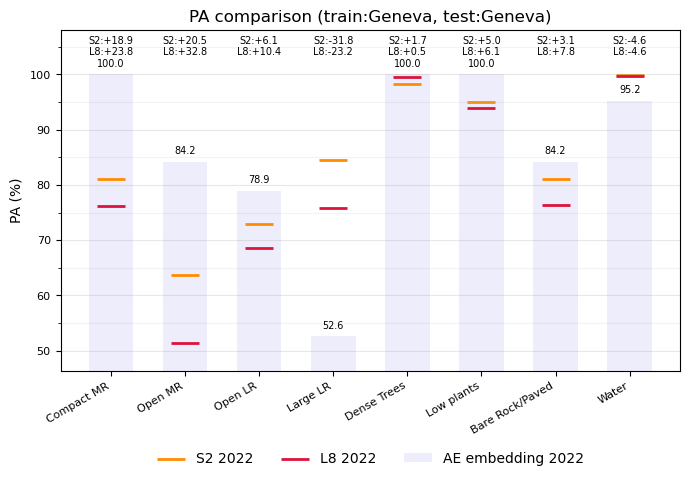

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    PA,
    width=0.6,
    alpha=0.7,
    color="lavender",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"PA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()})",
    fontsize=12
)

ax.set_ylabel("PA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(PA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

#ax.legend(bbox_to_anchor=(1, 1), loc='upper left')

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    f"./images/comparison_PA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

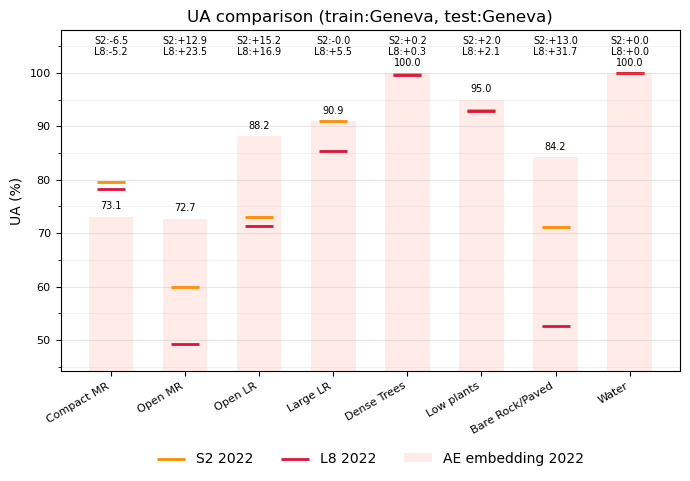

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    UA,
    width=0.6,
    alpha=0.7,
    color="mistyrose",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"UA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()})",
    fontsize=12
)

ax.set_ylabel("UA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(UA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)
plt.tight_layout()

plt.savefig(
    f"./images/comparison_UA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

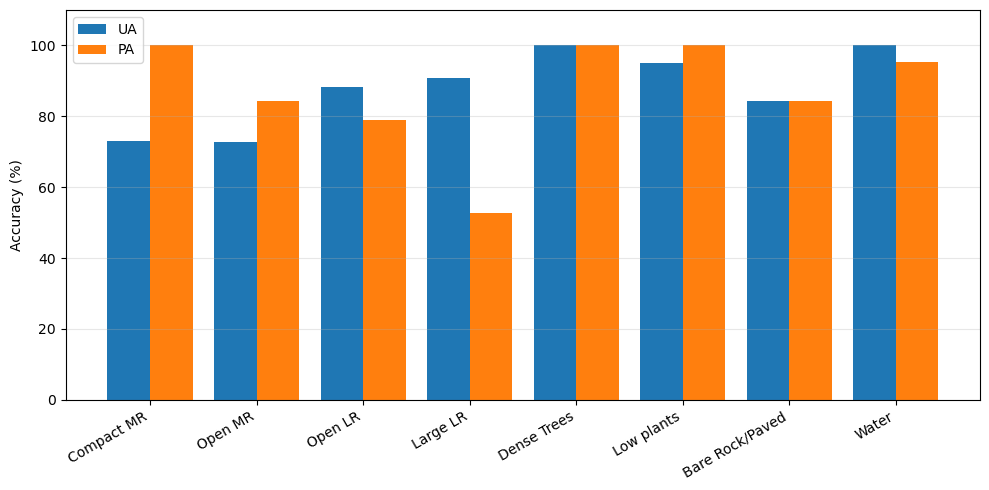

In [68]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(class_names))
width = 0.4

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - width/2, UA, width, label="UA")
ax.bar(x + width/2, PA, width, label="PA")

ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

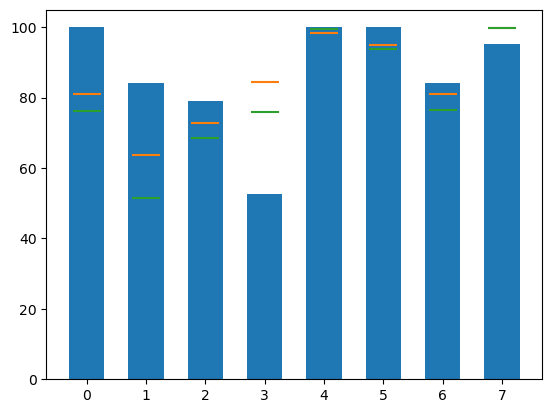

In [69]:
plt.bar(x, PA, width=0.6, label="AE embedding")

plt.scatter(
    x,
    ref_data[ref_city]["S2"]["PA"],
    marker="_",
    s=400,
    label="S2 2022"
)

plt.scatter(
    x,
    ref_data[ref_city]["L8"]["PA"],
    marker="_",
    s=400,
    label="L8 2022"
)

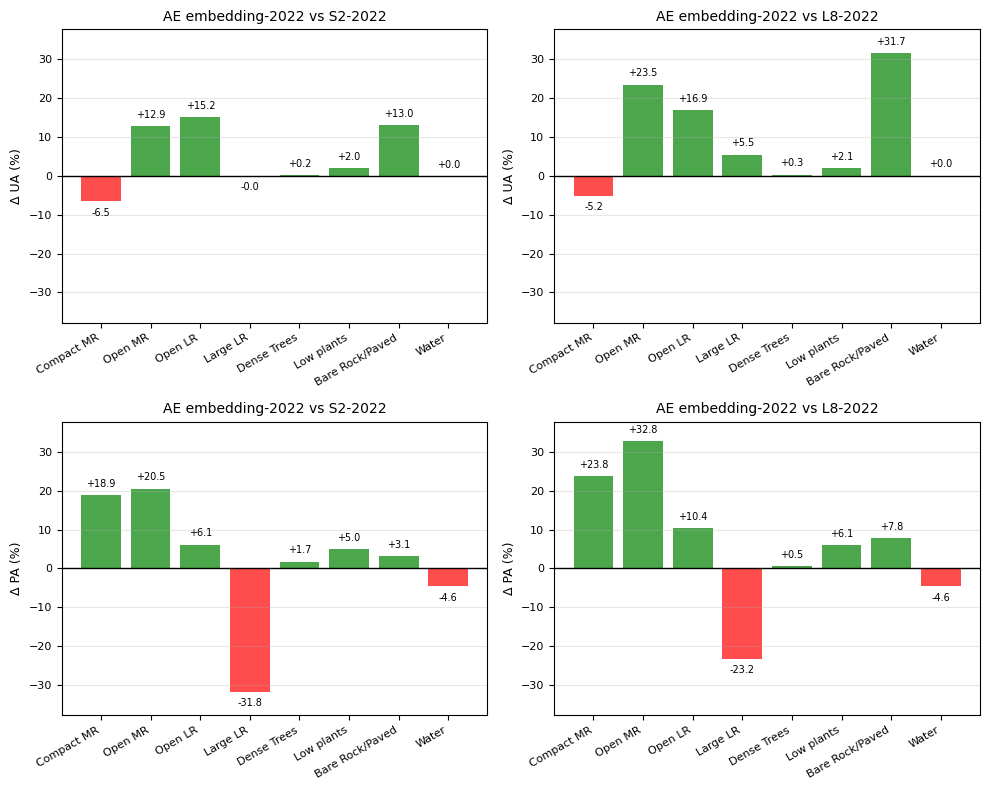

 Saved./images/validation_geneva_geneva_RF_500_8_5.png


In [70]:

# Defines data vs reference

ref_city = test_city.capitalize()

comparisons = [
    ("AE embedding-2022 vs S2-2022", "Δ UA (%)", UA, ref_data[ref_city]["S2"]["UA"]),
    ("AE embedding-2022 vs L8-2022", "Δ UA (%)", UA, ref_data[ref_city]["L8"]["UA"]),
    ("AE embedding-2022 vs S2-2022", "Δ PA (%)", PA, ref_data[ref_city]["S2"]["PA"]),
    ("AE embedding-2022 vs L8-2022", "Δ PA (%)", PA, ref_data[ref_city]["L8"]["PA"]),
]

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

# Compute common y-range for all subplots
max_diff = max(
    np.max(np.abs(data - ref))
    for _, _, data, ref in comparisons
)
#define pos and neg

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for ax, (title, ylabel, data, ref) in zip(axes, comparisons):

    diff = data - ref
    x = np.arange(len(class_names))

    colors = np.where(diff >= 0, "green", "red")

    ax.bar(x, diff, color=colors, alpha=0.7)

    # Reference level (difference = 0)
    ax.axhline(0, color="black", linewidth=1)

    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)

    # Same y-scale for all plots + extra space for annotations
    ax.set_ylim(-max_diff * 1.15, max_diff * 1.15)

    ax.set_xticks(x)
    ax.set_xticklabels(
        class_names,
        rotation=30,
        ha="right",
        fontsize=8
    )

    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", alpha=0.3)

    # Annotate differences
    offset = max_diff * 0.05

    for i, d in enumerate(diff):
        ax.text(
            i,
            d + np.sign(d) * offset,
            f"{d:+.1f}",
            ha="center",
            va="bottom" if d >= 0 else "top",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    f"./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png", 
    dpi=600, transparent=True, bbox_inches='tight')

plt.show()
print(f" Saved./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png")

### Visualize classified map

In [71]:
palette = [
    "#7A2A12",  # Compact MR
    "#DE6321",  # Open MR
    "#EAC89E",  # Open LR
    "#CFC9AE",  # Large LR
    "#5A772C",  # Dense Trees
    "#A2C766",  # Low plants
    "#4A442B",  # Bare Rock/Paved
    "#89C9E8"   # Water
]

#classified_vis = classified.remap(
#    [2, 5, 6, 8, 11, 14, 15, 17],
#    [1, 2, 3, 4, 5, 6, 7, 8]
#)

Map.addLayer(
  classified.clip(roi_basel),
  {"min": 1, "max": 8, "palette": palette},
  'Classified Satellite Embeddings Image');


#Map.add_basemap('SATELLITE')
Map

#print(train_centroids_gdf['macroclass_id'].value_counts())
#print(train_centroids.geometry().bounds().getInfo())
#print(roi.bounds().getInfo())


#Map.addLayer(train_centroids, {}, 'train points')
#Map.addLayer(embeddingsImage, {}, 'embeddings')
#Map

#print(training.first().getInfo())

NameError: name 'roi_basel' is not defined

In [ ]:
## Export classified map 

# Convert classes -> RGB image
classified_rgb = classified.visualize(
    min=1,
    max=8,
    palette=palette
)

# Export GeoTIFF
out_dir = "./images/"
geemap.ee_export_image(
    classified_rgb.clip(roi),
    filename=out_dir+f"classified_map_RGB_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.tif",
    scale=70,
    region=roi,
    file_per_band=False
)

# Export training points/polygons
geemap.ee_to_geojson(
    train_centroids,
    filename=out_dir+'training_points_v4.geojson'
)
Map

